# Лабораторная работа №3 — оптимизация гиперпараметров

**Задача:** предсказание `Survived = 1` для Titanic из [ЛР2](../lab2/lab02.ipynb). **Модель:** `GradientBoostingClassifier`; **метрика:** F1 положительного класса. Исходные требования: [ТЗ](materials/lab03.pdf), [презентация](materials/preza.pdf). Подробный протокол и список требований — в [PLAN.md](PLAN.md).

Используем тот же датасет, признаки и стратифицированное разбиение, что в ЛР2. В ЛР2 выбранная модель уже имела настройки `n_estimators=200`, `learning_rate=0.1`, `max_depth=3`. Это baseline данной работы. Её прежний test F1 уже известен по ЛР2; в этом notebook диапазоны и критерий выбора заданы заранее, а test оценивается только после Grid Search и Random Search. Полностью независимая оценка потребовала бы новой, ранее не раскрытой выборки.

**Порядок:** данные и baseline CV → сетка → случайный поиск → влияние параметров и устойчивость → выбор по CV → однократная итоговая оценка на test.

In [1]:
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import loguniform, randint
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import f1_score
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV, StratifiedKFold,
    cross_validate, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_STATE = 42
TEST_SIZE = 0.20
FOLDS = 5
N_JOBS = 1  # одинаковый параллелизм и условия измерения времени
SCORING = 'f1'  # положительный класс 1

numeric = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
categorical = ['Sex', 'Embarked']
features = numeric + categorical
baseline_params = dict(n_estimators=200, learning_rate=0.1,
                       max_depth=3, random_state=RANDOM_STATE)
param_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__learning_rate': [0.03, 0.1, 0.2],
    'model__max_depth': [1, 2, 3],
}
param_distributions = {
    'model__n_estimators': randint(100, 301),
    'model__learning_rate': loguniform(0.03, 0.2),
    'model__max_depth': randint(1, 4),
}
N_CANDIDATES = 27

## 1. Данные и честный протокол

ЛР2 использовала семь признаков. `Survived` служит только целевой переменной, а идентификаторы и текстовые поля в модель не попадают. Числовые пропуски заполняем медианой, категориальные — модой; категории кодируем One-Hot. Все обучаемые преобразования находятся **внутри `Pipeline`**: во время CV они переобучаются только на обучающих строках конкретного fold.

Фиксируем один split: 80% train и 20% test со стратификацией и `random_state=42`. Test не используется ни в CV, ни при выборе параметров. Датасет читается из ЛР2 без изменения исходного CSV.

In [2]:
data = pd.read_csv(Path('../lab2/data/Titanic-Dataset.csv'))
X = data[features]
y = data['Survived']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE,
)
assert data.shape == (891, 12)
assert set(y.unique()) == {0, 1}
assert 'Survived' not in X.columns
assert X_train.index.intersection(X_test.index).empty
display(pd.DataFrame({
    'строк': [len(y_train), len(y_test)],
    'доля Survived=1': [y_train.mean(), y_test.mean()],
}, index=['train', 'test']).round(3))

preprocessor = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median'))]), numeric),
    ('cat', Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), categorical),
])
base_pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', GradientBoostingClassifier(**baseline_params)),
])
cv = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=RANDOM_STATE)

,строк,доля Survived=1
train,712,0.383
test,179,0.385


**Вывод.** Разбиение воспроизведено: 712 пассажиров в train и 179 в test; доля выживших почти одинакова (38,3% и 38,5%). Test далее не используется до заключительного сравнения.

## 2. Baseline и зачем нужна CV

Baseline — прежний Gradient Boosting из ЛР2, где модель уже выбиралась по CV. Поэтому улучшение относительно него не гарантировано. Здесь считаем отдельную оценку **фиксированной** конфигурации на тех же пяти folds, что будут использовать оба поиска. `cross_validate` создаёт независимый экземпляр pipeline для каждого fold; статистики заполнения не видят validation строки.

Пять стратифицированных folds сохраняют доли классов и дают около 142 validation объектов на каждом шаге при 712 строках train. CV показывает, насколько качество зависит от конкретной разбивки. Одного train/test split для подбора недостаточно: выбор по одной проверочной части может случайно подстроиться под неё. Многократный выбор по test превращает его в обучающий сигнал и делает финальную оценку оптимистичной.

In [3]:
baseline_cv = cross_validate(
    base_pipeline, X_train, y_train, cv=cv, scoring=SCORING,
    return_train_score=True, n_jobs=N_JOBS, error_score='raise',
)
baseline_folds = baseline_cv['test_score']
display(pd.DataFrame({
    'fold': np.arange(1, FOLDS + 1),
    'train F1': baseline_cv['train_score'],
    'validation F1': baseline_folds,
}).round(3))
print(f'Baseline: mean CV F1 = {baseline_folds.mean():.4f}; '
      f'std = {baseline_folds.std(ddof=0):.4f}')

,fold,train F1,validation F1
0,1,0.921,0.785
1,2,0.921,0.743
2,3,0.906,0.796
3,4,0.921,0.752
4,5,0.922,0.745


Baseline: mean CV F1 = 0.7642; std = 0.0219


**Вывод по baseline.** Зафиксированная модель получила mean CV F1 **0,7642**, std **0,0219**; оценки отдельных folds лежат от **0,7429** до **0,7959**. Train F1 выше validation F1 на каждом fold, поэтому уже есть зазор обобщения. Прежний `best_score_` ЛР2 был около 0,764, но здесь он рассчитан заново для фиксированной конфигурации.

## 3. Гиперпараметры и бюджеты

| Параметр | Смысл и ожидаемое влияние | Сетка | Случайный поиск |
|---|---|---|---|
| `n_estimators` | Число последовательно добавляемых деревьев. Малое число может недообучать; большее повышает время и сложность. | 100, 200, 300 | Целые 100–300 |
| `learning_rate` | Вклад каждого дерева. Малые значения обычно требуют больше деревьев; большие могут переобучать. | 0.03, 0.1, 0.2 | Логарифмическое распределение 0.03–0.2 |
| `max_depth` | Сложность базового дерева. Глубокие деревья могут подгонять шум. | 1, 2, 3 | Целые 1–3 |

Grid Search проверяет все **3 × 3 × 3 = 27 комбинаций**, Random Search — **27 случайных комбинаций** из тех же границ. Для каждого поиска это **27 × 5 = 135 CV обучений** и один refit лучшего варианта на полном train. Время измеряем через `perf_counter` с одинаковым `n_jobs=1`. Сетка включает baseline `(200, 0.1, 3)`.

In [4]:
def results_table(search):
    raw = pd.DataFrame(search.cv_results_)
    columns = {
        'param_model__n_estimators': 'n_estimators',
        'param_model__learning_rate': 'learning_rate',
        'param_model__max_depth': 'max_depth',
        'mean_train_score': 'train F1',
        'mean_test_score': 'CV F1',
        'std_test_score': 'CV std',
        'rank_test_score': 'rank',
        **{f'split{i}_test_score': f'fold {i + 1}' for i in range(FOLDS)},
    }
    table = raw[list(columns)].rename(columns=columns)
    table.insert(0, '№', np.arange(1, len(table) + 1))
    return table.sort_values(['rank', '№']).reset_index(drop=True)


grid_search = GridSearchCV(
    base_pipeline, param_grid=param_grid, scoring=SCORING, cv=cv,
    n_jobs=N_JOBS, return_train_score=True, refit=True, error_score='raise',
)
started = perf_counter()
grid_search.fit(X_train, y_train)
grid_seconds = perf_counter() - started
grid_table = results_table(grid_search)
assert len(grid_table) == N_CANDIDATES
print(f'Grid Search: {len(grid_table)} комбинаций × {FOLDS} folds = '
      f'{len(grid_table) * FOLDS} CV обучений')
print('Лучшие параметры:', grid_search.best_params_)
print(f'Лучший mean CV F1 = {grid_search.best_score_:.4f}; '
      f'время с refit = {grid_seconds:.1f} с')
display(grid_table.round(4))

Grid Search: 27 комбинаций × 5 folds = 135 CV обучений
Лучшие параметры: {'model__learning_rate': 0.2, 'model__max_depth': 3, 'model__n_estimators': 200}
Лучший mean CV F1 = 0.7672; время с refit = 7.7 с


,№,n_estimators,learning_rate,max_depth,train F1,CV F1,CV std,rank,fold 1,fold 2,fold 3,fold 4,fold 5
0,26,200,0.20,3,0.9551,0.7672,0.0103,1,0.7619,0.7611,0.7767,0.7818,0.7547
1,17,200,0.10,3,0.9184,0.7642,0.0219,2,0.7850,0.7429,0.7959,0.7523,0.7451
2,16,100,0.10,3,0.8808,0.7580,0.0379,3,0.8190,0.7238,0.7789,0.7156,0.7525
3,27,300,0.20,3,0.9723,0.7553,0.0088,4,0.7619,0.7500,0.7692,0.7455,0.7500
4,23,200,0.20,2,0.9024,0.7550,0.0356,5,0.7963,0.7290,0.8000,0.7170,0.7327
5,25,100,0.20,3,0.9206,0.7545,0.0240,6,0.7925,0.7290,0.7723,0.7407,0.7379
6,15,300,0.10,2,0.8864,0.7526,0.0408,7,0.7963,0.7103,0.8000,0.7037,0.7525
7,18,300,0.10,3,0.9422,0.7519,0.0134,8,0.7736,0.7339,0.7525,0.7568,0.7429
8,9,300,0.03,3,0.8767,0.7512,0.0359,9,0.8113,0.7308,0.7629,0.7037,0.7475
9,24,300,0.20,2,0.9175,0.7502,0.0310,10,0.7818,0.7170,0.7921,0.7222,0.7379


**Вывод по сетке.** Проверены все **27** комбинаций. Лучший вариант — `n_estimators=200`, `learning_rate=0.2`, `max_depth=3`: mean CV F1 **0,7672**, std **0,0103**, полное время поиска с refit **7,7 с**. Прирост среднего относительно baseline составляет лишь **0,0030** F1. Близость результатов требует осторожной интерпретации: это не доказательство существенного улучшения.

## 4. Random Search с тем же бюджетом

`RandomizedSearchCV` с `n_iter=27` получает столько же CV обучений, что Grid Search. Случайный поиск может выбрать промежуточные `n_estimators` и `learning_rate`, которых нет в сетке; `random_state=42` делает набор воспроизводимым. Сравниваем его со Grid Search по mean CV F1, числу проверок и полному времени, включая refit. На этой небольшой задаче разница времени может зависеть от сложности выбранных комбинаций и фоновой нагрузки.

In [5]:
random_search = RandomizedSearchCV(
    base_pipeline, param_distributions=param_distributions,
    n_iter=N_CANDIDATES, random_state=RANDOM_STATE,
    scoring=SCORING, cv=cv, n_jobs=N_JOBS,
    return_train_score=True, refit=True, error_score='raise',
)
started = perf_counter()
random_search.fit(X_train, y_train)
random_seconds = perf_counter() - started
random_table = results_table(random_search)
sampled = random_table[['n_estimators', 'learning_rate', 'max_depth']]
unique_count = len(sampled.drop_duplicates())
assert len(random_table) == N_CANDIDATES
print(f'Random Search: {len(random_table)} проверок, '
      f'{unique_count} уникальных комбинаций, '
      f'{len(random_table) * FOLDS} CV обучений')
print('Лучшие параметры:', random_search.best_params_)
print(f'Лучший mean CV F1 = {random_search.best_score_:.4f}; '
      f'время с refit = {random_seconds:.1f} с')
display(random_table.round(4))

Random Search: 27 проверок, 27 уникальных комбинаций, 135 CV обучений
Лучшие параметры: {'model__learning_rate': np.float64(0.05212757105574501), 'model__max_depth': 3, 'model__n_estimators': 269}
Лучший mean CV F1 = 0.7671; время с refit = 8.1 с


,№,n_estimators,learning_rate,max_depth,train F1,CV F1,CV std,rank,fold 1,fold 2,fold 3,fold 4,fold 5
0,9,269,0.0521,3,0.8938,0.7671,0.0254,1,0.8037,0.7500,0.7879,0.7339,0.7600
1,17,271,0.0474,3,0.8921,0.7598,0.0327,2,0.8037,0.7429,0.7835,0.7091,0.7600
2,18,134,0.0768,3,0.8816,0.7584,0.0422,3,0.8190,0.7115,0.7835,0.7103,0.7677
3,10,289,0.0328,3,0.8797,0.7578,0.0395,4,0.8113,0.7238,0.7835,0.7027,0.7677
4,22,289,0.1483,2,0.9017,0.7567,0.0379,5,0.7963,0.7103,0.8000,0.7170,0.7600
5,5,249,0.0393,3,0.8814,0.7546,0.0408,6,0.8190,0.7238,0.7789,0.7037,0.7475
6,13,120,0.1533,3,0.9134,0.7545,0.0341,7,0.7736,0.7568,0.8000,0.6972,0.7451
7,23,147,0.1740,3,0.9340,0.7545,0.0186,8,0.7736,0.7207,0.7619,0.7664,0.7500
8,20,233,0.1257,2,0.8843,0.7541,0.0436,9,0.7963,0.7103,0.8119,0.7048,0.7475
9,26,287,0.0835,2,0.8735,0.7526,0.0374,10,0.7963,0.7222,0.8000,0.7170,0.7273


In [6]:
search_comparison = pd.DataFrame([
    {'поиск': 'Grid Search', 'комбинаций': len(grid_table),
     'уникальных': len(grid_table), 'CV обучений': len(grid_table) * FOLDS,
     'лучший CV F1': grid_search.best_score_, 'время, с': grid_seconds},
    {'поиск': 'Random Search', 'комбинаций': len(random_table),
     'уникальных': unique_count, 'CV обучений': len(random_table) * FOLDS,
     'лучший CV F1': random_search.best_score_, 'время, с': random_seconds},
])
display(search_comparison.round(3))

,поиск,комбинаций,уникальных,CV обучений,лучший CV F1,"время, с"
0,Grid Search,27,27,135,0.767,7.748
1,Random Search,27,27,135,0.767,8.115


**Сравнение стратегий.** Random Search проверил **27 уникальных** наборов при тех же **135 CV обучениях**. Лучший набор (`n_estimators=269`, `learning_rate≈0,0521`, `max_depth=3`) дал mean CV F1 **0,7671**, std **0,0254**; время с refit — **8,1 с**. Разница лучших средних между Grid и Random меньше **0,001** F1, поэтому по этому эксперименту нельзя объявлять один метод в целом точнее. Grid оказался немного быстрее в данном запуске, но скорость зависит и от сложности конкретных кандидатов. Random Search полезнее при большем или непрерывном пространстве и фиксированном бюджете, когда полный перебор слишком дорог.

## 5. Влияние параметров и устойчивость

Для графиков берём полную сетку Grid Search и меняем **один параметр за раз**, фиксируя два остальных на исходных значениях baseline. Линии показывают mean train F1 и mean validation F1; вертикальные отрезки — std CV по folds. Это контролируемые срезы пространства, а не зависимость, усреднённая по разным настройкам. Дополнительно показываем взаимодействие числа деревьев и скорости обучения при `max_depth=3`.

Признак недообучения — низкое качество даже на train; признак переобучения — рост train F1 без роста validation F1. Если в выбранном диапазоне какой-либо области не видно, не будем утверждать обратное.

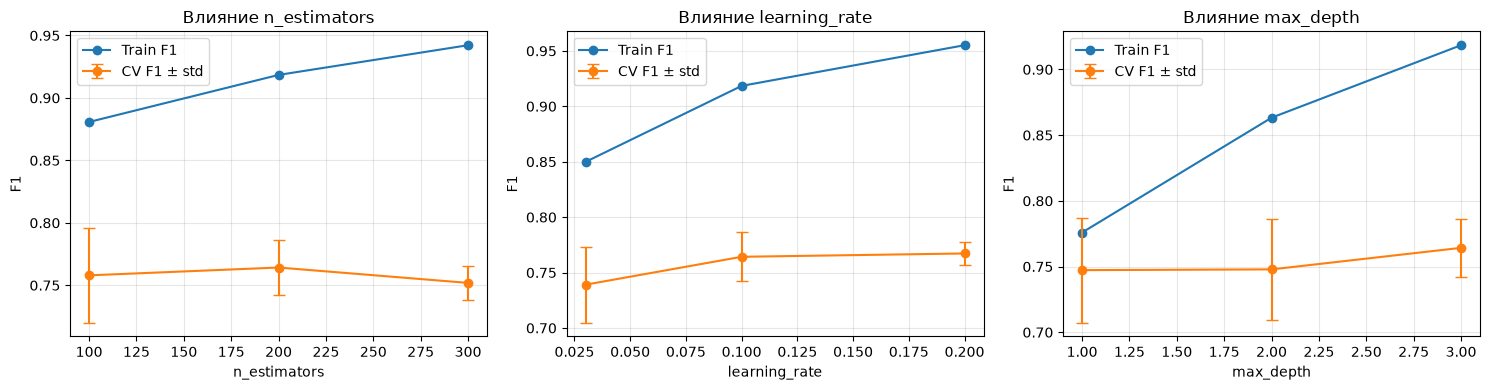

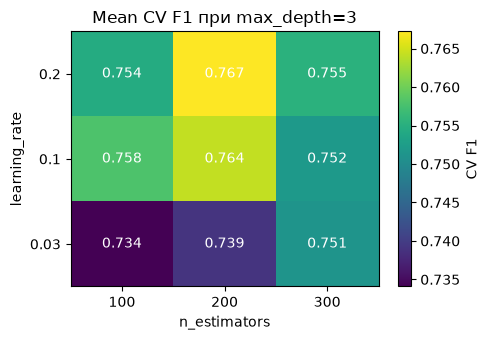

In [7]:
raw_grid = pd.DataFrame(grid_search.cv_results_)
for name in ('n_estimators', 'learning_rate', 'max_depth'):
    raw_grid[name] = raw_grid[f'param_model__{name}'].astype(float)

figure, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, parameter in zip(axes, ('n_estimators', 'learning_rate', 'max_depth')):
    others = [name for name in ('n_estimators', 'learning_rate', 'max_depth')
              if name != parameter]
    subset = raw_grid.loc[
        raw_grid[others[0]].eq(baseline_params[others[0]]) &
        raw_grid[others[1]].eq(baseline_params[others[1]])
    ].sort_values(parameter)
    assert len(subset) == 3
    ax.plot(subset[parameter], subset['mean_train_score'], marker='o', label='Train F1')
    ax.errorbar(subset[parameter], subset['mean_test_score'],
                yerr=subset['std_test_score'], marker='o', capsize=4,
                label='CV F1 ± std')
    ax.set(xlabel=parameter, ylabel='F1', title=f'Влияние {parameter}')
    ax.grid(alpha=0.3)
    ax.legend()
figure.tight_layout()
plt.show()

heat = raw_grid.loc[raw_grid['max_depth'].eq(3)].pivot(
    index='learning_rate', columns='n_estimators', values='mean_test_score',
).sort_index(ascending=False)
fig, ax = plt.subplots(figsize=(5, 3.5))
im = ax.imshow(heat.to_numpy(), cmap='viridis', aspect='auto')
ax.set_xticks(np.arange(len(heat.columns)), labels=heat.columns.astype(int))
ax.set_yticks(np.arange(len(heat.index)), labels=heat.index)
ax.set(xlabel='n_estimators', ylabel='learning_rate',
       title='Mean CV F1 при max_depth=3')
for (row, col), value in np.ndenumerate(heat.to_numpy()):
    ax.text(col, row, f'{value:.3f}', ha='center', va='center', color='white')
fig.colorbar(im, ax=ax, label='CV F1')
fig.tight_layout()
plt.show()

**Вывод по графикам.** При исходных двух остальных параметрах рост `n_estimators` с 100 до 200 повышает CV F1 с **0,758** до **0,764**, а рост до 300 снижает его до **0,752**, хотя train F1 продолжает расти: это наблюдаемый признак переобучения. При `learning_rate=0.03` train и CV F1 ниже, чем при 0.1–0.2; вместе с 200 деревьями это признак недостаточной обученности в рассмотренном диапазоне. Глубина 1 даёт train F1 около **0,776**, глубина 3 — около **0,918**; CV F1 повышается с **0,747** до **0,764**, поэтому для глубины 3 нельзя утверждать, что CV уже падает. Карта показывает взаимодействие числа деревьев и скорости обучения: при малой скорости большему числу деревьев требуется компенсировать слабый вклад каждого дерева. Срезы охватывают только заданные значения и не доказывают поведение вне них.

In [8]:
def best_fold_scores(search):
    return np.array([
        search.cv_results_[f'split{i}_test_score'][search.best_index_]
        for i in range(FOLDS)
    ])


fold_scores = {
    'Исходная модель': baseline_folds,
    'Лучший Grid': best_fold_scores(grid_search),
    'Лучший Random': best_fold_scores(random_search),
}
stability = pd.DataFrame({
    name: {**{f'fold {i + 1}': score for i, score in enumerate(scores)},
           'mean': scores.mean(), 'std': scores.std(ddof=0),
           'min': scores.min(), 'max': scores.max()}
    for name, scores in fold_scores.items()
}).T
display(stability.round(4))

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std,min,max
Исходная модель,0.7850,0.7429,0.7959,0.7523,0.7451,0.7642,0.0219,0.7429,0.7959
Лучший Grid,0.7619,0.7611,0.7767,0.7818,0.7547,0.7672,0.0103,0.7547,0.7818
Лучший Random,0.8037,0.7500,0.7879,0.7339,0.7600,0.7671,0.0254,0.7339,0.8037


**Устойчивость.** Почти равные средние Grid (**0,7672**) и Random (**0,7671**) скрывают разный разброс: std **0,0103** против **0,0254**, диапазоны fold F1 **0,7547–0,7818** против **0,7339–0,8037**. На этих пяти folds Grid устойчивее, однако это наблюдение для одного разбиения и не гарантирует преимущества на новых данных. Разброс возникает из-за различий состава небольших validation folds и чувствительности модели к обучающей части.

## 6. Выбор финальной конфигурации **до** оценки test

Выбираем лучший из двух поисков по **mean CV F1**. При точном равенстве предпочитаем меньший CV std, затем меньшую сложность (`max_depth`, `n_estimators`). Небольшая разница между mean CV F1 сама по себе не доказывает, что одна стратегия универсально лучше: folds и пространства конечны. Test не участвует в выборе.

In [9]:
def selection_key(item):
    _, search = item
    params = search.best_params_
    return (-search.best_score_,
            search.cv_results_['std_test_score'][search.best_index_],
            params['model__max_depth'], params['model__n_estimators'])


selected_name, selected_search = min(
    [('Grid Search', grid_search), ('Random Search', random_search)],
    key=selection_key,
)
print('Финальная конфигурация выбрана по CV до просмотра test:')
print(selected_name, selected_search.best_params_)
print(f'Mean CV F1 = {selected_search.best_score_:.4f}')

Финальная конфигурация выбрана по CV до просмотра test:
Grid Search {'model__learning_rate': 0.2, 'model__max_depth': 3, 'model__n_estimators': 200}
Mean CV F1 = 0.7672


## 7. Финальная оценка на test

Оба поиска с `refit=True` уже обучили лучшие модели на всём train. Теперь обучаем на всём train исходную конфигурацию и один раз получаем предсказания всех трёх моделей на одинаковом test. **После этой ячейки параметры и выбор модели не меняем.**

In [10]:
baseline_final = clone(base_pipeline).fit(X_train, y_train)
final_models = {
    'Исходная модель': baseline_final,
    'Лучший Grid': grid_search.best_estimator_,
    'Лучший Random': random_search.best_estimator_,
}
final_params = {
    'Исходная модель': baseline_params,
    'Лучший Grid': grid_search.best_params_,
    'Лучший Random': random_search.best_params_,
}
final_rows = []
for name, model in final_models.items():
    scores = fold_scores[name]
    final_rows.append({
        'модель': name,
        'n_estimators': final_params[name].get('model__n_estimators',
                                          final_params[name].get('n_estimators')),
        'learning_rate': final_params[name].get('model__learning_rate',
                                           final_params[name].get('learning_rate')),
        'max_depth': final_params[name].get('model__max_depth',
                                       final_params[name].get('max_depth')),
        'mean CV F1': scores.mean(),
        'std CV F1': scores.std(ddof=0),
        'test F1': f1_score(y_test, model.predict(X_test), pos_label=1),
    })
final_table = pd.DataFrame(final_rows).set_index('модель')
display(final_table.round(4))

,n_estimators,learning_rate,max_depth,mean CV F1,std CV F1,test F1
модель,,,,,,
Исходная модель,200,0.1000,3,0.7642,0.0219,0.7360
Лучший Grid,200,0.2000,3,0.7672,0.0103,0.7244
Лучший Random,269,0.0521,3,0.7671,0.0254,0.7258


**Итог.** По заранее объявленному правилу выбрана конфигурация Grid Search: её mean CV F1 **0,7672**, против **0,7642** у baseline и **0,7671** у Random Search. На локальном test F1 составил **0,7360** у baseline, **0,7244** у Grid и **0,7258** у Random. Следовательно, небольшой выигрыш Grid на CV (**+0,0030**) **не подтвердился** на test (изменение относительно baseline **−0,0116**). Random тоже не улучшил test (**−0,0102**). После просмотра test параметры и выбор не менялись: выбирать здесь baseline или Random как «победителя» означало бы использовать test для настройки. Расхождение согласуется с вариацией на 179 тестовых объектах, разбросом folds и смещением выбора лучшего среднего из множества кандидатов; причинно установить вклад каждого фактора по одному test нельзя. Результат этого test уже публиковался в ЛР2, поэтому независимая внешняя проверка остаётся ограничением.

## 8. Что объяснить на защите

- **CV:** каждый fold по очереди служит validation; test не участвует в выборе. Пять стратифицированных folds сохраняют долю класса 1 и показывают разброс качества.
- **Pipeline:** медиана, мода и One-Hot обучаются внутри каждого fold; иначе сведения из validation могут попасть в обучение.
- **Метрика:** F1 класса `Survived=1` объединяет precision и recall и совпадает с основной метрикой ЛР2. Accuracy может скрыть провал на положительном классе.
- **Параметры:** `n_estimators` задаёт число деревьев, `learning_rate` — вклад каждого, `max_depth` — сложность дерева. Их влияние взаимосвязано.
- **Grid и Random:** сетка проверяет все заранее выбранные точки; случайный поиск пробует ограниченное число точек, в том числе промежуточных. При одинаковом бюджете результат зависит от пространства и случайной выборки.
- **Интерпретация:** train F1 может расти при падающем CV F1; одинаковое среднее CV не означает одинаковый разброс по folds. Выбор лучшего из многих кандидатов слегка завышает его CV оценку.
- **Ограничения:** выигрыш по CV не подтвердился на локальном test; новую модель после этого не подбираем. Test уже был виден в ЛР2; полностью независимая оценка потребовала бы новых данных.
